# Новости и доходность акций РФ

**Вопрос:** есть ли в новостях информация о будущей избыточной доходности сверх цен?

Данные: 8 акций и IMOEX; новости — 2024–2025, посты MarketTwits — 2018–2025.
Запуск: зависимости из `requirements-analysis.txt`, затем Restart Kernel → Run All.
Функции и их проверки — в `src/news_eda.py` и `src/news_eda_checks.py`, описание данных — в `docs/DATA_PREPARATION.md`.

## 01 · Постановка

- Наблюдение — акция × сессия IMOEX; новость относится к первой сессии после московской даты публикации.
- Цель на 1/3/5 сессий: доходность от открытия этой сессии до закрытия окна минус то же для IMOEX.
- Цены открытия и закрытия — основная сессия по минуткам, 10:00–18:50 МСК: в эти часы считается IMOEX.
- Окна с пропусками, сменой масштаба цены или дивидендами исключаются.
- Посты MarketTwits с точным временем — отдельно: внутри дня (раздел 05) и по дням (раздел 06).
- 2025 год уже исследовался, поэтому проверка на нём диагностическая.

In [ ]:
from collections import OrderedDict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.constrained_layout.use"] = True

ROOT = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / "data/ru_eda_2024_2026/docs.parquet").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Не найден data/ru_eda_2024_2026: откройте ноутбук из папки проекта.")
# Функции — в src/ рядом с ноутбуком; папка ищется по файлу, её имя не важно
sys.path.insert(0, str(next(path.parent for path in [*Path.cwd().glob("src/news_eda.py"), *ROOT.glob("*/src/news_eda.py")])))
from src.news_eda import (
    BPS, HORIZONS, LATE_OPEN_MINUTE, NEWS_COUNTS, RELEVANCE_EPS, RELEVANCE_THRESHOLD, SESSION_START, TZ, adjust_fdr,
    aggregate_news, assert_unique, audit_document_integrity, best_post_similarity, bootstrap_by_day,
    bootstrap_loss_comparison, clean_news_mask, estimate_news_association, finite_mean, forward_windows,
    load_markettwits, main_session_bars, make_folds, next_session, panel_with_news, predict_walk_forward,
    show_figure, show_table, tone_difference,
)
from src.news_eda_checks import run_code_checks

In [2]:
# --- Параметры исследования; параметры методов (горизонты, пороги, HAC, bootstrap) — в news_eda.py ---
START, END = pd.Timestamp("2024-01-01"), pd.Timestamp("2026-01-01")
TICKERS = ["SBER", "GAZP", "LKOH", "GMKN", "NVTK", "PLZL", "ROSN", "VTBR"]
STOCKS = [f"MOEX:{ticker}" for ticker in TICKERS]
BENCHMARK = "MOEX:IMOEX"
IDS = STOCKS + [BENCHMARK]
MT_SIMILARITY = 0.35  # порог TF-IDF для совпадения новости и поста MarketTwits

DATA = ROOT / "data/ru_eda_2024_2026"
EXTRAS = DATA / "extras"  # тональность, события и ставка из S3, отраслевые индексы, GPT-метки
MARKETTWITS = DATA / "markettwits_web.jsonl"  # посты с точным временем
checks = OrderedDict()  # проверки кода, итог — в приложении

## 02 · Качество данных

Независимая дата документа — из датировки текста («Регнум»), из даты в URL или по порядковому номеру статьи в URL.
Карантин: `published_at` раньше независимой даты или позже неё больше чем на день (по номеру — больше чем на 30 дней),
либо `title` не совпадает с первой строкой текста. Карантин сверяется с постами MarketTwits.

In [3]:
all_news = pd.read_parquet(DATA / "docs.parquet")
links = pd.read_parquet(DATA / "news_instruments.parquet")
flags = pd.read_parquet(DATA / "doc_flags.parquet")
daily_quotes = pd.read_parquet(DATA / "daily/ru_daily.parquet", filters=[("instrument_id", "in", IDS)])
dividends = pd.read_parquet(DATA / "daily/ru_dividends.parquet")
actions = pd.read_parquet(
    DATA / "reference/corporate_actions_v2.parquet", filters=[("instrument_id", "in", STOCKS)]
)
calendar = pd.read_parquet(DATA / "reference/trading_calendar.parquet")

assert_unique(all_news, ["doc_id"], "documents")
assert_unique(links, ["doc_id", "instrument_id"], "links")
assert_unique(daily_quotes, ["instrument_id", "trade_date"], "daily")
assert links.doc_id.isin(all_news.doc_id).all(), "Есть связи без документа"
checks["Уникальные ключи документов, связей и дневных свечей"] = True
checks["Все связи имеют документ"] = True

for frame, column in [(daily_quotes, "trade_date"), (dividends, "ex_date"), (actions, "ex_date"), (calendar, "date")]:
    frame[column] = pd.to_datetime(frame[column], errors="coerce")
daily_quotes["ticker"] = daily_quotes.instrument_id.str.removeprefix("MOEX:")
all_news["published_at"] = pd.to_datetime(all_news.published_at, utc=True)
all_news["publication_date"] = all_news.published_at.dt.tz_convert(TZ).dt.tz_localize(None).dt.normalize()

In [4]:
flag_summary = flags.groupby("doc_id", as_index=False).agg(
    flag_recap=("is_price_recap", "max"),
    flag_date=("date_suspect", "max"),
    flag_lang=("lang_suspect", "max"),
    flag_body=("has_body", "max"),
)
all_news = all_news.merge(flag_summary, on="doc_id", how="left", validate="one_to_one")
# Документ без исходных флагов считается подозрительным по дате и языку.
all_news["date_bad"] = all_news.date_suspect.fillna(True) | all_news.flag_date.fillna(True)
all_news["lang_bad"] = all_news.lang_suspect.fillna(True) | all_news.flag_lang.fillna(True)
all_news["recap"] = all_news.is_price_recap.fillna(False) | all_news.flag_recap.fillna(False)
all_news["has_body"] = all_news.text.fillna("").str.strip().ne("") & all_news.flag_body.eq(True)
all_news["midnight_utc"] = all_news.published_at.eq(all_news.published_at.dt.normalize())
all_news = all_news.join(audit_document_integrity(all_news), validate="one_to_one")

all_news = all_news.sort_values(["publication_date", "published_at", "doc_id"], ignore_index=True)
all_news["hash_key"] = all_news.text_hash.where(all_news.text_hash.fillna("").ne(""), all_news.doc_id)
news = all_news.loc[all_news.publication_date.ge(START) & all_news.publication_date.lt(END)].copy()

integrity_audit = news.groupby("source").agg(
    документов=("doc_id", "size"),
    полночь_UTC=("midnight_utc", "mean"),
    дата_проверена=("date_checked", "sum"),
    конфликт_даты=("date_conflict", "sum"),
    конфликт_заголовков=("title_body_conflict", "sum"),
    карантин=("integrity_quarantine", "sum"),
).reset_index()
integrity_audit["конфликт_среди_проверенных"] = integrity_audit.конфликт_даты / integrity_audit.дата_проверена
show_table(integrity_audit, "Карантин по источникам, 2024–2025",
           {"полночь_UTC": "{:.0%}", "конфликт_среди_проверенных": "{:.1%}"})

source,документов,полночь_UTC,дата_проверена,конфликт_даты,конфликт_заголовков,карантин,конфликт_среди_проверенных
ccnews,"42,870",78%,"37,142","8,086",70,"8,087",21.8%
lenta,"1,326",0%,"1,326",3,0,3,0.2%


In [5]:
# Есть ли почти такой же пост MarketTwits в ±1 день от даты документа; окно, сдвинутое на 30 дней, — доля случайных совпадений.
mt_posts = load_markettwits(MARKETTWITS, START - pd.Timedelta(days=40), END + pd.Timedelta(days=40))
russian = news.loc[news.lang.eq("ru")]
similarity = best_post_similarity(russian.title, russian.publication_date, mt_posts)
similarity_null = best_post_similarity(russian.title, russian.publication_date, mt_posts, shift_days=30)
group = np.select([russian.integrity_quarantine, russian.date_checked], ["карантин", "дата подтверждена"], "дата не проверена")
markettwits_check = pd.DataFrame({"группа": group, "подтверждено": similarity >= MT_SIMILARITY,
                                  "случайно": similarity_null >= MT_SIMILARITY}).groupby("группа").agg(
    документов=("подтверждено", "size"), подтверждено=("подтверждено", "mean"), случайно=("случайно", "mean"),
).reset_index()
show_table(markettwits_check, "Совпадение с постом MarketTwits ±1 день, русские документы 2024–2025",
           {"подтверждено": "{:.1%}", "случайно": "{:.1%}"})

группа,документов,подтверждено,случайно
дата не проверена,966,2.5%,0.1%
дата подтверждена,"29,633",6.9%,0.2%
карантин,"8,088",0.2%,0.0%


**Цены.** Open и close акций и IMOEX — из минуток основной сессии: первая сделка с 10:00 и последняя до 18:50 МСК.
В дневных свечах MOEX у акций есть утренняя и вечерняя сессии, когда IMOEX не считается.
Пропуски не заполняются; от открытия позже 10:05 цель не считается.
Известный сплит или изменение close более чем в 2 раза — разрыв ряда: доходность через него не считается.

In [6]:
INTRADAY_START = pd.Timestamp("2018-01-01")
MINUTE_FILES = [ROOT / "data/ru_quotes_2018_2023/quotes_1m.parquet", DATA / "quotes_1m.parquet"]  # ISS напрямую и из S3

bars = pd.concat([
    pd.read_parquet(path, columns=["instrument_id", "bar_ts", "open", "high", "low", "close", "value", "ohlc_valid"],
                    filters=[("instrument_id", "in", IDS)])
    .assign(bar_ts=lambda f: pd.to_datetime(f.bar_ts, utc=True))
    for path in MINUTE_FILES
], ignore_index=True)
assert not bars.duplicated(["instrument_id", "bar_ts"]).any(), "Минута есть в обоих файлах"
checks["Минутки ISS и S3 не пересекаются"] = True
bar_time = bars.bar_ts.dt.tz_convert(TZ)
bars["day"] = bar_time.dt.tz_localize(None).dt.normalize()
bars["minute"] = bar_time.dt.hour * 60 + bar_time.dt.minute - SESSION_START
bars = bars.loc[bars.ohlc_valid]
main_bars = main_session_bars(bars)
bars = bars.drop(columns=["open", "high", "low"])  # дальше нужны только close и оборот

# Цены дневной свечи заменяются ценами основной сессии; состав сессий и оборот остаются из дневного файла.
daily_quotes = daily_quotes.loc[daily_quotes.trade_date.ge(INTRADAY_START) & daily_quotes.trade_date.lt(END)]
daily_quotes = (daily_quotes.assign(had_bar=daily_quotes.close.notna()).drop(columns=["open", "high", "low", "close"])
                .merge(main_bars.rename(columns={"day": "trade_date"}), on=["instrument_id", "trade_date"],
                       how="left", validate="one_to_one"))
assert daily_quotes.close.notna().eq(daily_quotes.had_bar).all(), "Дневная свеча без минуток основной сессии"
checks["У каждой дневной свечи 2018–2025 есть минутки основной сессии"] = True
daily_quotes["late_open"] = daily_quotes.open_minute.gt(LATE_OPEN_MINUTE)
print(f"Свечей основной сессии: {int(daily_quotes.had_bar.sum()):,}; с открытием позже 10:05: {int(daily_quotes.late_open.sum())}.")

Свечей основной сессии: 18,071; с открытием позже 10:05: 13.


In [7]:
raw_daily = daily_quotes.loc[daily_quotes.trade_date.ge(START) & daily_quotes.trade_date.lt(END)]
sessions = pd.DatetimeIndex(raw_daily.loc[raw_daily.instrument_id.eq(BENCHMARK), "trade_date"].unique()).sort_values()
expected_sessions = pd.DatetimeIndex(calendar.loc[
    calendar.exchange.eq("XMOS_SHARES") & calendar.is_trading.eq(True)
    & calendar.date.ge(START) & calendar.date.lt(END),
    "date",
].unique()).sort_values()

missing_index_dates = expected_sessions.difference(sessions)
if len(missing_index_dates):
    raise ValueError(f"IMOEX отсутствует в {len(missing_index_dates)} датах календаря")
checks["Дневной IMOEX покрывает сессии локального календаря"] = True

In [8]:
grid = pd.MultiIndex.from_product([IDS, sessions], names=["instrument_id", "trade_date"]).to_frame(index=False)
prices = (grid.merge(raw_daily, on=["instrument_id", "trade_date"], how="left", validate="one_to_one")
          .sort_values(["instrument_id", "trade_date"]).reset_index(drop=True))
prices["ticker"] = prices.instrument_id.str.removeprefix("MOEX:")
prices["late_open"] = prices.late_open.eq(True)  # у пропущенной свечи открытия нет

ohlc = prices[["open", "high", "low", "close"]]
prices["valid_bar"] = (
    np.isfinite(ohlc).all(axis=1)
    & ohlc.gt(0).all(axis=1)
    & prices.high.eq(ohlc.max(axis=1))
    & prices.low.eq(ohlc.min(axis=1))
)

In [9]:
price_keys = pd.MultiIndex.from_frame(prices[["instrument_id", "trade_date"]])


def on_event_days(events):
    """True в сессиях, совпадающих с ex_date события инструмента."""
    event_keys = pd.MultiIndex.from_frame(events[["instrument_id", "ex_date"]].dropna())
    return price_keys.isin(event_keys)


prices["dividend"] = on_event_days(pd.concat([
    dividends[["instrument_id", "ex_date"]],
    actions.loc[actions.type.eq("dividend"), ["instrument_id", "ex_date"]],
]))
prices["known_split"] = on_event_days(actions.loc[actions.type.eq("split")])

In [10]:
by_instrument = prices.groupby("instrument_id", sort=False)
previous_close = by_instrument.close.shift(1)
last_observed_close = by_instrument.close.transform(lambda s: s.where(s.gt(0)).ffill().shift(1))

prices["observed_ratio"] = prices.close / last_observed_close
prices["scale_break"] = prices.observed_ratio.gt(2) | prices.observed_ratio.lt(0.5) | prices.known_split
prices["segment"] = prices.groupby("instrument_id").scale_break.cumsum()

both_bars_valid = prices.valid_bar & by_instrument.valid_bar.shift(1, fill_value=False)
prices["r_cc"] = (prices.close / previous_close - 1).where(both_bars_valid & ~prices.scale_break)
prices["r_cc_no_div"] = prices.r_cc.where(~prices.dividend)

breaks = prices.loc[prices.scale_break, ["ticker", "trade_date", "close", "observed_ratio", "known_split"]]
show_table(breaks, "Разрывы ряда цен: доходность через них не считается", {"observed_ratio": "{:.4f}"})

ticker,trade_date,close,observed_ratio,known_split
VTBR,2024-07-15 00:00:00,92.650,0.9309,True


## 03 · Панель

Отбор связей: релевантность ≥ 0,7, русский текст, нет recap, исходных флагов и карантина;
точные повторы удаляются по каждой акции. Ценовые признаки — за прошлую сессию.

$$
a(d)=\min\lbrace s : s>d \rbrace,\qquad
y_{i,a,H}=\left(\frac{C_{i,a+H-1}}{O_{i,a}}-1\right)-\left(\frac{C_{m,a+H-1}}{O_{m,a}}-1\right)
$$

$d$ — дата публикации, $a$ — первая сессия после неё; $C$, $O$ — цены закрытия и открытия основной сессии; $i$ — акция, $m$ — IMOEX (вычитается с β = 1); $H$ — горизонт в сессиях.

In [11]:
news_links = links[["doc_id", "instrument_id", "max_relevance"]].merge(news, on="doc_id", how="inner", validate="many_to_one")
assert len(news_links) == links.doc_id.isin(news.doc_id).sum()
checks["Соединение новостей не размножает связи"] = True
news_links["ticker"] = news_links.instrument_id.str.removeprefix("MOEX:")
news_links["high_relevance"] = news_links.max_relevance.ge(RELEVANCE_THRESHOLD - RELEVANCE_EPS)
news_links["clean"] = clean_news_mask(news_links)

filters = OrderedDict([
    ("Все связи", pd.Series(True, index=news_links.index)),
    ("Релевантность ≥0,7", news_links.high_relevance),
    ("Язык и текст", news_links.lang.eq("ru") & news_links.has_body & ~news_links.lang_bad),
    ("Исходные дата/recap", ~news_links.date_bad & ~news_links.recap),
    ("Без карантина", ~news_links.integrity_quarantine),
    ("Без повторов внутри акции", news_links.clean),
])
stage, selection_flow = pd.Series(True, index=news_links.index), []
for label, condition in filters.items():
    stage &= condition
    selection_flow.append(dict(этап=label, связей=int(stage.sum()), документов=news_links.loc[stage, "doc_id"].nunique()))
show_table(pd.DataFrame(selection_flow), "Отбор связей")
quarantined_eligible = news_links.loc[clean_news_mask(news_links, exclude_repeats=False, policy="metadata")
                                      & news_links.integrity_quarantine]

этап,связей,документов
Все связи,"53,400","44,196"
"Релевантность ≥0,7","19,529","18,955"
Язык и текст,"18,061","17,646"
Исходные дата/recap,"18,014","17,601"
Без карантина,"14,690","14,348"
Без повторов внутри акции,"14,688","14,346"


In [12]:
# Тональность документа (rubert-tiny2) и событие пары документ–акция (events_v2); оба из S3.
doc_sentiment = pd.read_parquet(EXTRAS / "doc_sentiment.parquet", columns=["doc_id", "sent"])
events = (pd.read_parquet(EXTRAS / "events.parquet", columns=["canonical_doc_id", "entity_id", "event_type", "novelty"])
          .rename(columns={"canonical_doc_id": "doc_id", "entity_id": "instrument_id"})
          .drop_duplicates(["doc_id", "instrument_id"]))
news_links = (news_links.merge(doc_sentiment, on="doc_id", how="left", validate="many_to_one")
              .merge(events, on=["doc_id", "instrument_id"], how="left", validate="one_to_one"))
selected = news_links.loc[news_links.clean]
print(f"В отборе: тональность у {selected.sent.notna().mean():.1%} связей, событие у {selected.event_type.notna().mean():.1%}; "
      f"положительных {selected.sent.gt(0).mean():.0%}.")

В отборе: тональность у 100.0% связей, событие у 96.0%; положительных 65%.


In [13]:
stock_days = prices[prices.instrument_id.isin(STOCKS)].copy()
stock_days["vol20"] = stock_days.groupby(["instrument_id", "segment"]).r_cc.transform(
    lambda returns: returns.rolling(20, min_periods=20).std())
stock_days["lag_vol20"] = stock_days.groupby("instrument_id").vol20.shift(1)

targets = forward_windows(prices)
# Открытие позже 10:05 (сбой торгов) не синхронно с индексом: цель от него не считается.
targets.loc[targets.late_open, [f"raw_y_{h}" for h in HORIZONS]] = np.nan
for h in HORIZONS:
    bench = targets[targets.instrument_id.eq(BENCHMARK)].set_index("trade_date")[f"raw_y_{h}"]
    targets[f"y_{h}"] = (targets[f"raw_y_{h}"] - targets.trade_date.map(bench)).where(
        ~targets[f"div_window_{h}"]
    )
label_columns = [c for c in targets if c.startswith(("y_", "raw_y_", "end_", "div_window_"))]
stock_days = stock_days.merge(targets[["instrument_id", "trade_date"] + label_columns],
                              on=["instrument_id", "trade_date"], how="left", validate="one_to_one")
news_links["anchor"] = next_session(news_links.publication_date, sessions)
news_links["anchor_plus1"] = next_session(news_links.publication_date, sessions, extra_delay=1)
aligned = news_links.anchor.notna()
assert news_links.loc[aligned, "anchor"].gt(news_links.loc[aligned, "publication_date"]).all()
checks["Якорь строго позже московской даты публикации"] = True

In [14]:
counts = aggregate_news(news_links)
panel = stock_days.merge(counts, on=["instrument_id", "trade_date"], how="left", validate="one_to_one")
panel[NEWS_COUNTS] = panel[NEWS_COUNTS].fillna(0).astype(int)
panel = panel.sort_values(["instrument_id", "trade_date"]).reset_index(drop=True)
group = panel.groupby("instrument_id", sort=False)
panel["lag_r"] = group.r_cc_no_div.shift(1)
panel["lag_log_value"] = np.log1p(group.value.shift(1).where(lambda s: s.ge(0)))
panel["log_news"] = np.log1p(panel.n_clean)
panel["weekday"] = panel.trade_date.dt.dayofweek.astype(str)
panel["quarter"] = panel.trade_date.dt.to_period("Q").astype(str)
assert_unique(panel, ["instrument_id", "trade_date"], "stock-day panel")
assert len(panel) == len(sessions) * len(STOCKS)
checks["Ровно одна строка акция × дневная сессия"] = True

tone = (news_links.loc[news_links.clean & news_links.anchor.notna()]
        .groupby(["instrument_id", "anchor"]).agg(sent_mean=("sent", "mean"))
        .rename_axis(["instrument_id", "trade_date"]).reset_index())
panel = panel.merge(tone, on=["instrument_id", "trade_date"], how="left", validate="one_to_one")
# Избыточная доходность прошлой сессии — обычно это сессия дня публикации.
market_return = prices.loc[prices.instrument_id.eq(BENCHMARK)].set_index("trade_date").r_cc
panel["excess_r"] = panel.r_cc_no_div - panel.trade_date.map(market_return)
panel["lag_excess"] = panel.groupby("instrument_id").excess_r.shift(1)
assert_unique(panel, ["instrument_id", "trade_date"], "panel with tone")

## 04 · Связь с будущей доходностью

- **Регрессия:** разность доходности дней с публикацией и без; контроль — прошлая доходность, оборот, квартал, день недели.
  Ошибки HAC (10 лагов) по сетке сессий, поправка BY на 8 акций × 3 горизонта. Меньше 40 дней в группе или квартал без одной из групп — мало данных.
- **Все бумаги:** та же регрессия по всей панели с эффектом бумаги; в HAC наблюдения одной сессии суммируются (Driscoll–Kraay).
- **Тональность:** положительные минус отрицательные новостные дни — в сессию публикации и в следующую.
- **Типы событий и новизна:** |избыточная доходность| в дни с событием к среднему дню той же бумаги. С днями без новостей сравнить нельзя: у SBER, GAZP и VTBR их почти нет.

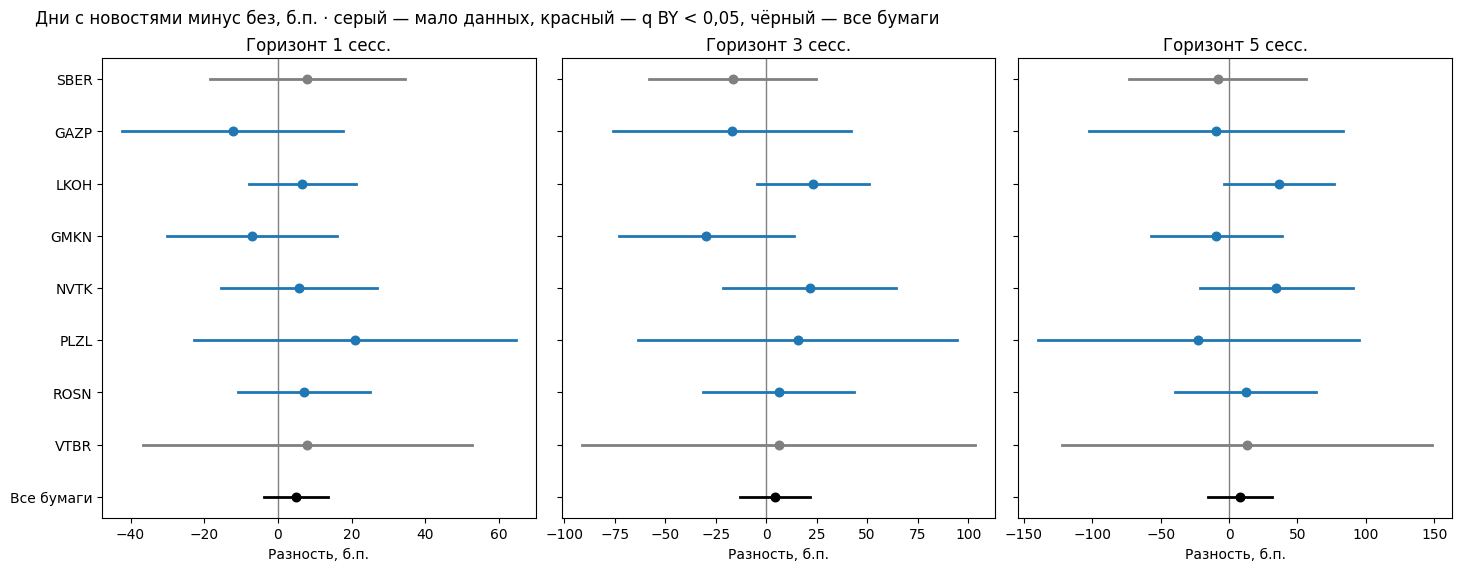

BY q < 0,05: 0 из 24.
Все бумаги: H=1 +4.9 б.п. [-3.8; +13.7]; H=3 +4.3 б.п. [-12.9; +21.5]; H=5 +8.0 б.п. [-15.1; +31.1].


In [15]:
ALL_STOCKS = "Все бумаги"
main = pd.DataFrame([
    dict(ticker=ticker, horizon=horizon, **estimate_news_association(stock_data, "n_clean", horizon, sessions))
    for ticker, stock_data in panel.groupby("ticker") for horizon in HORIZONS
])
main["q_BY"] = adjust_fdr(main.p)
pooled_main = pd.DataFrame([
    dict(horizon=horizon, **estimate_news_association(panel, "n_clean", horizon, sessions, pooled=True)) for horizon in HORIZONS
]).set_index("horizon")

fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.6), sharey=True)
for ax, horizon in zip(axes, HORIZONS):
    stock_data = main[main.horizon.eq(horizon)].set_index("ticker").reindex(TICKERS)
    ax.axvline(0, color="gray", lw=1)
    for i, row in enumerate(stock_data.itertuples()):
        color = "gray" if row.limited_support else ("C3" if row.q_BY < 0.05 else "C0")
        ax.plot([row.low_bps, row.high_bps], [i, i], color=color, lw=2)
        ax.scatter(row.beta_bps, i, s=38, color=color, zorder=3)
    total = pooled_main.loc[horizon]
    ax.plot([total.low_bps, total.high_bps], [len(TICKERS)] * 2, color="black", lw=2)
    ax.scatter(total.beta_bps, len(TICKERS), s=38, color="black", zorder=3)
    ax.set(title=f"Горизонт {horizon} сесс.", xlabel="Разность, б.п.")
axes[0].set_yticks(np.arange(len(TICKERS) + 1), TICKERS + [ALL_STOCKS])
axes[0].invert_yaxis()
show_figure(fig, "Дни с новостями минус без, б.п. · серый — мало данных, красный — q BY < 0,05, чёрный — все бумаги")
print(f"BY q < 0,05: {int(main.q_BY.lt(0.05).sum())} из {int(main.p.notna().sum())}.")
print(f"{ALL_STOCKS}: " + "; ".join(
    f"H={h} {row.beta_bps:+.1f} б.п. [{row.low_bps:+.1f}; {row.high_bps:+.1f}]" for h, row in pooled_main.iterrows()) + ".")

In [16]:
TONE_TARGETS = {"сессия публикации": "lag_excess", "следующая сессия": "y_1"}
tone_results = pd.DataFrame([
    dict(ticker=ticker, target=label, **tone_difference(stock_data, column, sessions))
    for label, column in TONE_TARGETS.items() for ticker, stock_data in panel.groupby("ticker")
])
tone_results["q_BY"] = adjust_fdr(tone_results.p)
tone_pooled = pd.DataFrame([dict(ticker=ALL_STOCKS, target=label, **tone_difference(panel, column, sessions, pooled=True))
                            for label, column in TONE_TARGETS.items()])
show_table(pd.concat([tone_pooled, tone_results], ignore_index=True),
           "Тональность: положительные минус отрицательные дни, б.п. · HAC 95%",
           {c: "{:.1f}" for c in ["beta_bps", "low_bps", "high_bps"]} | {"p": "{:.3f}", "q_BY": "{:.3f}"})
tone_summary = tone_results.groupby("target", sort=False).agg(
    оценено=("beta_bps", "count"), q_BY_ниже_005=("q_BY", lambda s: int(s.lt(0.05).sum())))

ticker,target,N_pos,N_neg,beta_bps,low_bps,high_bps,p,q_BY
Все бумаги,сессия публикации,"1,621",659,13.6,3.2,24.1,0.010,—
Все бумаги,следующая сессия,"1,623",663,10.9,0.4,21.4,0.042,—
GAZP,сессия публикации,293,175,20.7,0.7,40.7,0.043,0.441
GMKN,сессия публикации,87,39,8.8,-38.8,56.5,0.715,1.000
LKOH,сессия публикации,99,102,14.0,-17.4,45.4,0.380,1.000
NVTK,сессия публикации,79,58,61.1,15.5,106.7,0.009,0.146
PLZL,сессия публикации,42,13,-28.9,-129.9,72.0,0.568,1.000
ROSN,сессия публикации,285,46,12.8,-11.0,36.7,0.290,1.000
SBER,сессия публикации,398,93,2.1,-13.8,18.0,0.796,1.000
VTBR,сессия публикации,338,133,4.0,-24.0,31.9,0.779,1.000


In [17]:
# |избыточная доходность| в дни с событием данного типа к среднему дню той же бумаги за все сессии.
REACTION = {"lag_excess": "публикация", "y_1": "следующая"}
baseline = panel.groupby("ticker")[list(REACTION)].agg(lambda s: s.abs().mean())
event_days = (news_links.loc[news_links.clean & news_links.anchor.notna()]
              .assign(event_type=lambda f: f.event_type.fillna("other"))
              .groupby(["ticker", "anchor"]).agg(types=("event_type", set), novelty=("novelty", "max"))
              .rename_axis(["ticker", "day"]).reset_index()
              .merge(panel[["ticker", "trade_date", *REACTION]].rename(columns={"trade_date": "day"}),
                     on=["ticker", "day"], validate="one_to_one")
              .dropna(subset=list(REACTION)))  # в обоих столбцах таблицы одни и те же дни
assert set(event_days.ticker) == set(TICKERS)
checks["В таблице типов событий участвуют все бумаги"] = True
for column in REACTION:
    event_days[f"abs_{column}"] = event_days[column].abs()
    event_days[f"base_{column}"] = event_days.ticker.map(baseline[column])

median_novelty = event_days.novelty.median()
groups = {"все дни с новостями": event_days.index.notna(),
          "новизна выше медианы": event_days.novelty.gt(median_novelty),
          "новизна ниже медианы": event_days.novelty.le(median_novelty)}
type_counts = event_days.types.explode().value_counts()
groups |= {f"тип: {t}": event_days.types.map(lambda s, t=t: t in s) for t in type_counts.index[type_counts.ge(30)]}

event_rows = []
for name, mask in groups.items():
    data = event_days.loc[mask]
    row = {"группа": name, "дней": len(data)}
    for column, label in REACTION.items():
        stats_ = bootstrap_by_day(data, f"abs_{column}", f"base_{column}")
        row |= {f"{label}_×": stats_["оценка"], f"{label}_low": stats_["low"], f"{label}_high": stats_["high"]}
    event_rows.append(row)
event_reaction = pd.DataFrame(event_rows)
show_table(event_reaction, "|AR| в дни с событием, раз к среднему дню бумаги · 95% bootstrap по датам",
           {c: "{:.2f}" for c in event_reaction.columns if c not in ("группа", "дней")})

группа,дней,публикация_×,публикация_low,публикация_high,следующая_×,следующая_low,следующая_high
все дни с новостями,"2,269",1.00,0.95,1.05,0.99,0.95,1.04
новизна выше медианы,"1,117",1.01,0.94,1.09,0.99,0.92,1.06
новизна ниже медианы,"1,126",0.99,0.92,1.06,1.00,0.94,1.07
тип: other,"2,108",1.00,0.94,1.05,0.98,0.93,1.03
тип: macro,178,1.08,0.94,1.22,1.07,0.92,1.22
тип: sanctions,173,1.15,0.97,1.34,1.11,0.95,1.28
тип: legal,171,0.99,0.86,1.14,1.04,0.89,1.21
тип: earnings,155,1.12,0.94,1.32,1.16,0.92,1.48
тип: dividend,129,1.37,1.08,1.74,1.18,0.99,1.37
тип: buyback_spo,35,1.17,0.90,1.49,0.83,0.58,1.15


## 05 · Реакция внутри дня

Посты MarketTwits с тикером в хэштеге (#SBER, #GAZP…), 2018–2025; минутные свечи MOEX ISS.
- Событие — пост в основную сессию с полным окном ±60 минут; посты о бумаге в течение часа — одно событие.
- Реакция — |избыточная доходность к IMOEX| и оборот в окне против тех же минут в ±20 сессиях без постов о бумаге.
- Продолжение — идёт ли цена после поста в сторону движения за 10 минут до него, против контрольных дней.
- Знак новости — GPT-разметка постов о GAZP, LKOH, NVTK, ROSN (`extras/labels_gpt_v2.csv`); посты со знаком, взятым из цены в тексте, исключены. Знак × AR показывает, идёт ли цена в сторону новости; «+1» — первая минута после минуты поста, «+2…+60» — вход через минуту после неё.

In [18]:
SESSION_MINUTES = 520  # непрерывные торги 10:00–18:40 МСК; минутки загружены в разделе 02
EVENT_GAP_MINUTES = 60
CONTROL_SESSIONS = 20
# Окно (a, b): изменение от конца минуты k+a до конца минуты k+b, k — минута поста.
WINDOWS = {"−60…−11": (-61, -11), "−10…−1": (-11, -1), "минута поста": (-1, 0),
           "+1…+10": (0, 10), "+11…+30": (10, 30), "+31…+60": (30, 60)}

intraday_sessions = pd.DatetimeIndex(daily_quotes.loc[
    daily_quotes.instrument_id.eq(BENCHMARK) & daily_quotes.trade_date.ge(INTRADAY_START) & daily_quotes.trade_date.lt(END),
    "trade_date"].unique()).sort_values()
bars = bars.loc[bars.minute.between(0, SESSION_MINUTES - 1) & bars.day.isin(intraday_sessions)]


def session_matrix(instrument, column):
    """Сессия × минута от 10:00."""
    frame = bars.loc[bars.instrument_id.eq(instrument)].pivot(index="day", columns="minute", values=column)
    return frame.reindex(index=intraday_sessions, columns=range(SESSION_MINUTES)).to_numpy()


# Цена на конец минуты — последняя сделка; избыточная доходность к IMOEX с β = 1.
log_price = {i: pd.DataFrame(np.log(session_matrix(i, "close"))).ffill(axis=1).to_numpy() for i in IDS}
abnormal_path = {i: log_price[i] - log_price[BENCHMARK] for i in STOCKS}
turnover = {i: np.nan_to_num(session_matrix(i, "value")) for i in STOCKS}

In [19]:
intraday_posts = load_markettwits(MARKETTWITS, INTRADAY_START, END)
tags = intraday_posts.text.str.findall(r"#(\w+)").map(lambda found: sorted({t.upper() for t in found} & set(TICKERS)))
tagged_posts = intraday_posts.assign(ticker=tags).explode("ticker").dropna(subset=["ticker"]).reset_index(drop=True)
post_events = tagged_posts.loc[tagged_posts.day.isin(intraday_sessions)].sort_values("date")
post_time = post_events.date.dt.tz_convert(TZ)
post_events = post_events.assign(minute=post_time.dt.hour * 60 + post_time.dt.minute - SESSION_START)
post_days = post_events.groupby("ticker").day.agg(set)

repeat = post_events.date - post_events.groupby("ticker").date.shift() <= pd.Timedelta(minutes=EVENT_GAP_MINUTES)
first_minute = -min(a for a, _ in WINDOWS.values())
last_minute = SESSION_MINUTES - 1 - max(b for _, b in WINDOWS.values())
intraday_events = post_events.loc[~repeat & post_events.minute.between(first_minute, last_minute),
                                  ["id", "date", "ticker", "day", "minute", "text"]]
print(f"Постов с тикером в дни сессий: {len(post_events):,}; событий с полным окном ±60 мин: {len(intraday_events):,}.")

Постов с тикером в дни сессий: 14,850; событий с полным окном ±60 мин: 5,236.


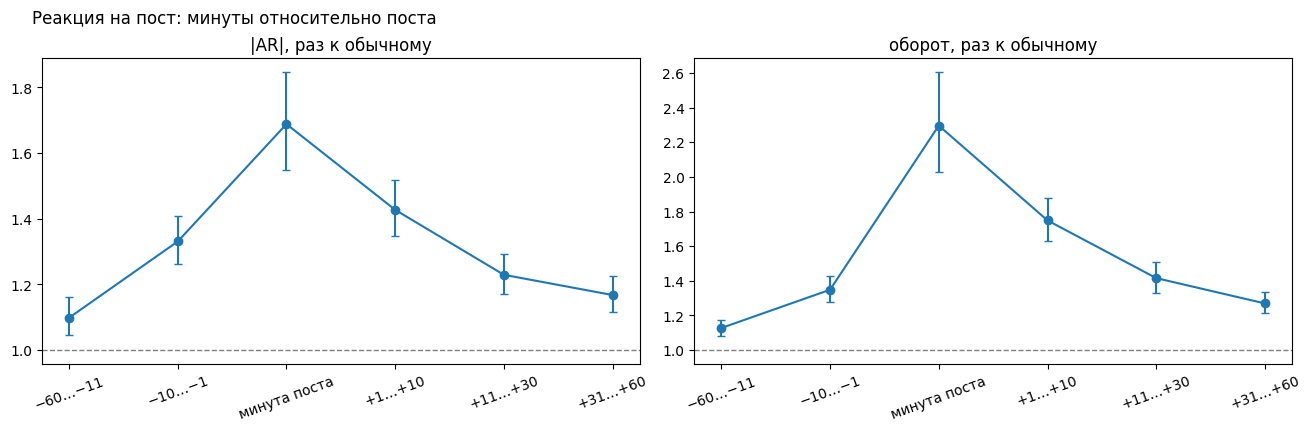

year,событий,−10…−1,минута поста,+1…+10,+11…+30
2018,365,1.20 [1.03; 1.41],1.08 [0.94; 1.21],1.14 [1.00; 1.29],1.11 [0.99; 1.24]
2019,"1,218",1.24 [1.12; 1.37],1.21 [1.08; 1.38],1.20 [1.10; 1.32],1.21 [1.11; 1.32]
2020,981,1.19 [1.08; 1.31],1.25 [1.10; 1.43],1.25 [1.14; 1.38],1.12 [1.02; 1.22]
2021,766,1.22 [1.12; 1.34],1.21 [1.10; 1.33],1.28 [1.17; 1.38],1.13 [1.05; 1.22]
2022,479,1.46 [1.15; 1.86],1.79 [1.38; 2.27],1.59 [1.29; 1.92],1.25 [1.02; 1.56]
2023,486,1.59 [1.39; 1.81],3.55 [2.86; 4.33],2.00 [1.64; 2.47],1.72 [1.40; 2.10]
2024,377,1.50 [1.30; 1.72],2.81 [2.30; 3.41],1.66 [1.47; 1.89],1.26 [1.10; 1.42]
2025,400,1.68 [1.40; 2.00],2.68 [1.76; 4.21],2.05 [1.56; 2.82],1.31 [1.14; 1.49]


In [20]:
def control_rows(ticker, day):
    """Сессии в ±CONTROL_SESSIONS без постов о бумаге."""
    position = intraday_sessions.get_loc(day)
    nearby = np.zeros(len(intraday_sessions), bool)
    nearby[max(0, position - CONTROL_SESSIONS): position + CONTROL_SESSIONS + 1] = True
    return position, np.flatnonzero(nearby & ~intraday_sessions.isin(post_days[ticker]))


def window_reaction(events):
    rows = []
    for event in events.itertuples():
        path, volume = abnormal_path[f"MOEX:{event.ticker}"], turnover[f"MOEX:{event.ticker}"]
        position, control = control_rows(event.ticker, event.day)
        for name, (a, b) in WINDOWS.items():
            start, end = event.minute + a, event.minute + b
            rows.append(dict(
                day=event.day, ticker=event.ticker, window=name,
                abs_ar=abs(path[position, end] - path[position, start]),
                abs_ar_control=finite_mean(np.abs(path[control, end] - path[control, start])),
                value=volume[position, start + 1:end + 1].sum(),
                value_control=finite_mean(volume[control, start + 1:end + 1].sum(axis=1)),
            ))
    return pd.DataFrame(rows).dropna()


reaction = window_reaction(intraday_events)
intraday_summary = pd.concat({
    "|AR|, раз к обычному": reaction.groupby("window").apply(
        bootstrap_by_day, "abs_ar", "abs_ar_control", include_groups=False),
    "оборот, раз к обычному": reaction.groupby("window").apply(
        bootstrap_by_day, "value", "value_control", include_groups=False),
}, axis=1).reindex(list(WINDOWS))
show_table(intraday_summary.reset_index(), "Реакция на пост MarketTwits по окнам · 95% bootstrap по датам",
           {column: "{:,.0f}" if column[1] == "событий" else "{:.2f}" for column in intraday_summary.columns})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, column in zip(axes, ["|AR|, раз к обычному", "оборот, раз к обычному"]):
    values = intraday_summary[column]
    positions = np.arange(len(values))
    ax.errorbar(positions, values["оценка"], yerr=[values["оценка"] - values["low"], values["high"] - values["оценка"]],
                fmt="o-", capsize=3)
    ax.axhline(1, color="gray", lw=1, ls="--")
    ax.set_xticks(positions, values.index, rotation=20)
    ax.set_title(column)
show_figure(fig, "Реакция на пост: минуты относительно поста")

KEY_WINDOWS = ["−10…−1", "минута поста", "+1…+10", "+11…+30"]
intraday_by_year = (reaction.loc[reaction.window.isin(KEY_WINDOWS)].assign(year=lambda f: f.day.dt.year)
                    .groupby(["year", "window"]).apply(bootstrap_by_day, "abs_ar", "abs_ar_control", include_groups=False)
                    .apply(lambda row: f"{row.оценка:.2f} [{row.low:.2f}; {row.high:.2f}]", axis=1).unstack()[KEY_WINDOWS])
intraday_by_year.insert(0, "событий", reaction.loc[reaction.window.eq("+1…+10")].groupby(reaction.day.dt.year).size())
show_table(intraday_by_year.reset_index(), "|AR| по годам, раз к обычному · 95% bootstrap по датам", {"year": "{:d}"})

In [21]:
def signed_continuation(events, before=(-11, 0), after=(0, 10)):
    """sign(AR за 10 минут до поста и в минуту поста) × AR через 1–10 минут, б.п.: событие и контроль."""
    rows = []
    for event in events.itertuples():
        path = abnormal_path[f"MOEX:{event.ticker}"]
        position, control = control_rows(event.ticker, event.day)
        k = event.minute

        def move(rows_, window):
            return path[rows_, k + window[1]] - path[rows_, k + window[0]]

        rows.append(dict(day=event.day,
                         event=np.sign(move(position, before)) * move(position, after) * BPS,
                         control=finite_mean(np.sign(move(control, before)) * move(control, after)) * BPS))
    return pd.DataFrame(rows).dropna()


continuation = signed_continuation(intraday_events)
continuation["difference"] = continuation.event - continuation.control
continuation_summary = pd.DataFrame({
    "событие": bootstrap_by_day(continuation, "event"),
    "контроль": bootstrap_by_day(continuation, "control"),
    "разница": bootstrap_by_day(continuation, "difference"),
}).T.reset_index(names="ряд")
show_table(continuation_summary, "Продолжение движения после поста, б.п. · > 0 — в сторону движения до поста",
           {"событий": "{:,.0f}", "оценка": "{:.2f}", "low": "{:.2f}", "high": "{:.2f}"})

ряд,событий,оценка,low,high
событие,"5,072",0.64,-0.18,1.54
контроль,"5,072",-0.65,-0.79,-0.51
разница,"5,072",1.30,0.46,2.19


In [22]:
# Знак GPT-метки × AR: те же события, у которых пост размечен со знаком; ±2 считаются как ±1.
LABELS = EXTRAS / "labels_gpt_v2.csv"
labels = pd.read_csv(LABELS, sep=";", usecols=["id", "ts", "kind", "target", "price_in_text", "sign"])
labels = labels.loc[labels.kind.eq("company") & labels.target.isin(TICKERS) & labels.price_in_text.eq(0)].rename(columns={"target": "ticker"})
signed_events = intraday_events.merge(labels[["id", "ticker", "sign"]], on=["id", "ticker"], validate="one_to_one")
signed_events = signed_events.loc[signed_events.sign.ne(0)].assign(sign=lambda f: np.sign(f.sign))

SIGNED_WINDOWS = {"−60…−11": (-61, -11), "−10…−1": (-11, -1), "минута поста": (-1, 0), "+1": (0, 1),
                  "+2…+10": (1, 10), "+11…+30": (10, 30), "+31…+60": (30, 60), "+2…+60": (1, 60)}
signed_moves = []
for event in signed_events.itertuples():
    path = abnormal_path[f"MOEX:{event.ticker}"][intraday_sessions.get_loc(event.day)]
    signed_moves.append({"day": event.day} | {name: event.sign * (path[event.minute + b] - path[event.minute + a]) * BPS
                                              for name, (a, b) in SIGNED_WINDOWS.items()})
signed_moves = pd.DataFrame(signed_moves)
intraday_sign = pd.DataFrame({name: bootstrap_by_day(signed_moves.dropna(subset=[name]), name)
                              for name in SIGNED_WINDOWS}).T.reset_index(names="окно")
show_table(intraday_sign, "Знак GPT-метки × AR по окнам, б.п. · > 0 — цена идёт в сторону новости · 95% bootstrap по датам",
           {"событий": "{:,.0f}", "оценка": "{:+.1f}", "low": "{:+.1f}", "high": "{:+.1f}"})
print(f"Событий со знаком: {len(signed_events)} (позитив {int(signed_events.sign.gt(0).sum())}, "
      f"негатив {int(signed_events.sign.lt(0).sum())}).")

окно,событий,оценка,low,high
−60…−11,338,+5.6,+2.0,+9.2
−10…−1,338,+4.1,+0.9,+7.7
минута поста,338,-0.0,-2.0,+2.0
+1,338,+1.9,+0.5,+3.3
+2…+10,338,+1.8,-0.9,+4.5
+11…+30,338,+1.3,-1.2,+3.8
+31…+60,338,+1.4,-1.8,+4.5
+2…+60,338,+4.5,-0.6,+9.4


Событий со знаком: 338 (позитив 231, негатив 107).


## 06 · Реакция по дням

Те же посты, 2018–2025, и дневные свечи основной сессии.
- День 0 — первая сессия, основные торги которой закончились после поста: пост после 18:50 относится к следующей сессии; посты о бумаге за сессию — одно событие.
- AR — close-to-close доходность акции минус IMOEX; без дней дивидендов, смены масштаба и первой сессии после паузы торгов 2022 года.
- Контроль — те же сдвиги от сессий без постов о бумаге в ±20 сессиях.
- Знак новости — та же GPT-разметка, что в разделе 05.

In [23]:
DAILY_OFFSETS = np.arange(-5, 6)
MAX_SESSION_GAP_DAYS = 7  # торги акциями не шли 25.02–23.03.2022


def daily_abnormal_returns(sessions):
    """Сессия × тикер: r_cc акции − r_cc IMOEX; правила раздела 02 и пропуск первой сессии после паузы."""
    wide = daily_quotes.pivot(index="trade_date", columns="instrument_id", values=["open", "high", "low", "close"]).reindex(sessions)
    o, h, l, c = (wide[field][IDS] for field in ["open", "high", "low", "close"])
    valid = o.gt(0) & l.gt(0) & h.ge(o) & h.ge(c) & l.le(o) & l.le(c)

    def on_ex_date(events):
        hits = pd.crosstab(events.ex_date, events.instrument_id).reindex(index=sessions, columns=IDS, fill_value=0)
        return hits.gt(0)

    ratio = c / c.where(c.gt(0)).ffill().shift()
    scale_break = ratio.gt(2) | ratio.lt(0.5) | on_ex_date(actions.loc[actions.type.eq("split")])
    dividend = on_ex_date(pd.concat([dividends[["instrument_id", "ex_date"]],
                                     actions.loc[actions.type.eq("dividend"), ["instrument_id", "ex_date"]]]))
    r = (c / c.shift() - 1).where(valid & valid.shift(fill_value=False) & ~scale_break)
    r.loc[sessions.to_series().diff().dt.days.gt(MAX_SESSION_GAP_DAYS)] = np.nan  # первая сессия после паузы
    ar = r[STOCKS].sub(r[BENCHMARK], axis=0).where(~dividend[STOCKS])
    return ar.rename(columns=lambda i: i.removeprefix("MOEX:"))


daily_ar = daily_abnormal_returns(intraday_sessions)
ar_matrix = np.vstack([np.full((5, len(TICKERS)), np.nan), daily_ar[TICKERS].to_numpy(),
                       np.full((5, len(TICKERS)), np.nan)])  # 5 пустых строк по краям: сдвиги −5…+5 без проверки границ
print(f"Дневных AR: {int(daily_ar.notna().sum().sum()):,} из {daily_ar.size:,} акция-сессий 2018–2025.")

# Сессия поста: первая, у которой конец последней свечи основной сессии позже поста; без минуток — 18:50.
to_utc = lambda times: times.dt.tz_convert("UTC").dt.tz_localize(None).to_numpy()
last_trade = main_bars.set_index(["instrument_id", "day"]).last_bar.dt.tz_convert(TZ)  # начало последней свечи
fallback_close = pd.Series(intraday_sessions + pd.Timedelta(hours=18, minutes=50), index=intraday_sessions).dt.tz_localize(TZ)
close_time = np.column_stack([
    to_utc((last_trade[f"MOEX:{ticker}"].reindex(intraday_sessions) + pd.Timedelta(minutes=1)).fillna(fallback_close))
    for ticker in TICKERS])  # сессия × тикер, конец последней свечи


def session_position(times, ticker):
    """Номер сессии реакции в intraday_sessions; len(intraday_sessions) — после конца выборки."""
    return np.searchsorted(close_time[:, TICKERS.index(ticker)], to_utc(times), side="left")


tagged_posts["position"] = 0
for ticker, index in tagged_posts.groupby("ticker").groups.items():
    tagged_posts.loc[index, "position"] = session_position(tagged_posts.loc[index, "date"], ticker)
daily_events = tagged_posts.loc[tagged_posts.position.lt(len(intraday_sessions))].drop_duplicates(["ticker", "position"])
daily_events = daily_events.assign(day=intraday_sessions[daily_events.position]).sort_values(["ticker", "position"])

column = daily_events.ticker.map(TICKERS.index).to_numpy()
post_utc, position = to_utc(daily_events.date), daily_events.position.to_numpy()
checks["Пост раньше закрытия своей сессии и позже закрытия предыдущей"] = bool(
    (post_utc <= close_time[position, column]).all()
    and ((position == 0) | (post_utc > close_time[np.maximum(position - 1, 0), column])).all())

has_post = np.zeros((len(intraday_sessions), len(TICKERS)), bool)
has_post[position, column] = True
print(f"Событий (бумага × сессия с постом): {len(daily_events):,}; доля сессий с постом: "
      + ", ".join(f"{t} {share:.0%}" for t, share in zip(TICKERS, has_post.mean(axis=0))) + ".")

Дневных AR: 15,948 из 16,080 акция-сессий 2018–2025.
Событий (бумага × сессия с постом): 6,638; доля сессий с постом: SBER 52%, GAZP 72%, LKOH 38%, GMKN 33%, NVTK 38%, PLZL 17%, ROSN 42%, VTBR 40%.


In [24]:
def daily_windows(events):
    """Для события: AR на сдвигах −5…+5, средние |AR| и продолжение по контрольным сессиям той же бумаги."""
    result = []
    for event in events.itertuples():
        column = TICKERS.index(event.ticker)
        nearby = np.arange(max(0, event.position - CONTROL_SESSIONS),
                           min(len(intraday_sessions), event.position + CONTROL_SESSIONS + 1))
        control = nearby[~has_post[nearby, column]]
        event_ar = ar_matrix[event.position + 5 + DAILY_OFFSETS, column]
        control_ar = ar_matrix[control[:, None] + 5 + DAILY_OFFSETS, column]  # контрольная сессия × сдвиг
        control_sign = np.sign(control_ar[:, 5])
        result.append(dict(
            ar=event_ar,
            abs_control=[finite_mean(np.abs(control_ar[:, k])) for k in range(len(DAILY_OFFSETS))],
            next_control=finite_mean(control_sign * control_ar[:, 6]),
            later_control=finite_mean(control_sign * control_ar[:, 7:].sum(axis=1)),
        ))
    return result


windows = daily_windows(daily_events)
event_ar = np.vstack([w["ar"] for w in windows])  # событие × сдвиг −5…+5
by_offset = pd.DataFrame({
    "day": daily_events.day.repeat(len(DAILY_OFFSETS)).to_numpy(),
    "ticker": daily_events.ticker.repeat(len(DAILY_OFFSETS)).to_numpy(),
    "k": np.tile(DAILY_OFFSETS, len(daily_events)),
    "abs_ar": np.abs(event_ar).ravel(),
    "abs_control": np.concatenate([w["abs_control"] for w in windows]),
}).dropna()
daily_abs_profile = by_offset.groupby("k").apply(bootstrap_by_day, "abs_ar", "abs_control", include_groups=False)

# sign(AR дня 0) × AR следующих дней минус то же для контрольных сессий
direction = np.sign(event_ar[:, 5])
daily_reaction = pd.DataFrame({
    "day": daily_events.day.to_numpy(),
    "ticker": daily_events.ticker.to_numpy(),
    "next_difference": (direction * event_ar[:, 6] - [w["next_control"] for w in windows]) * BPS,
    "later_difference": (direction * event_ar[:, 7:].sum(axis=1) - [w["later_control"] for w in windows]) * BPS,
})
daily_continuation = pd.DataFrame({
    name: bootstrap_by_day(daily_reaction.dropna(subset=[column]), column)
    for name, column in [("день +1", "next_difference"), ("дни +2…+5", "later_difference")]
}).T.reset_index(names="окно")
show_table(daily_continuation, "Продолжение движения дня 0 к контролю, б.п. · > 0 — в ту же сторону",
           {"событий": "{:,.0f}", "оценка": "{:.1f}", "low": "{:.1f}", "high": "{:.1f}"})

# Держится ли продолжение на одной бумаге: та же оценка без каждой бумаги по очереди.
later = daily_reaction.dropna(subset=["later_difference"])
leave_one_out = pd.DataFrame({ticker: bootstrap_by_day(later.loc[later.ticker.ne(ticker)], "later_difference")
                              for ticker in TICKERS}).T
weakest = leave_one_out.оценка.idxmin()
leave_one_out_note = "от {:+.1f} б.п. [{:+.1f}; {:+.1f}] (без {}) до {:+.1f} б.п. (без {})".format(
    *leave_one_out.loc[weakest, ["оценка", "low", "high"]], weakest, leave_one_out.оценка.max(), leave_one_out.оценка.idxmax())
print(f"Дни +2…+5 без одной бумаги: {leave_one_out_note}.")

окно,событий,оценка,low,high
день +1,"6,338",-1.3,-5.2,2.4
дни +2…+5,"6,243",12.6,4.8,20.6


Дни +2…+5 без одной бумаги: от +1.7 б.п. [-6.3; +9.6] (без GAZP) до +17.1 б.п. (без LKOH).


Размеченных постов: 1,761; сессий со знаком и полным окном −5…+5: 701 (позитив 472, негатив 229).


окно,позитив,негатив,знак × AR,low,high
дни −5…−2,+35.2,+15.5,+18.6,+0.3,+37.4
день −1,+14.1,-7.6,+12.0,+0.0,+25.4
день 0,+37.8,-19.6,+31.9,+17.6,+47.2
день +1,-2.8,+2.6,-2.7,-12.5,+6.6
дни +2…+5,+21.0,+14.9,+9.3,-8.2,+24.9


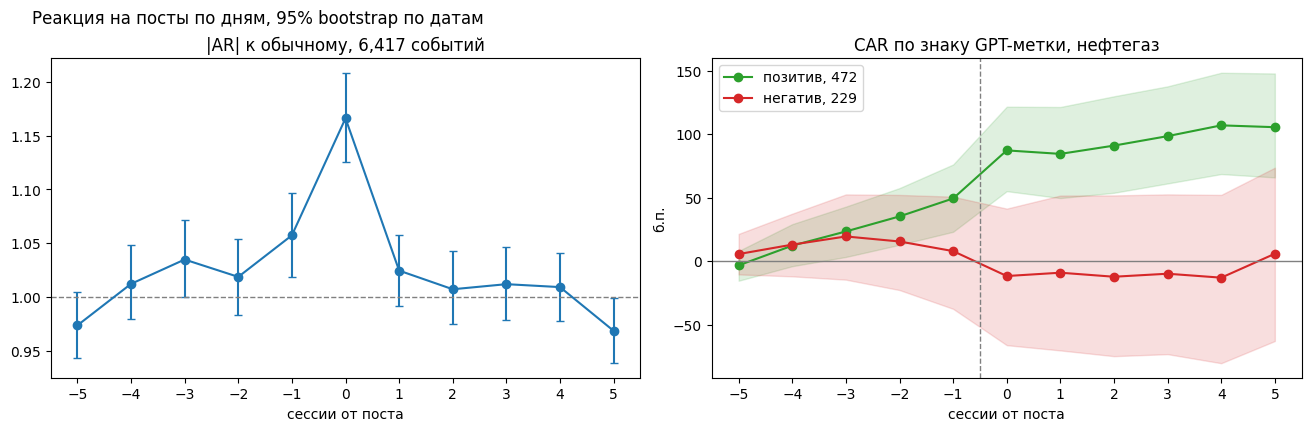

In [25]:
labels["date"] = pd.to_datetime(labels.ts).dt.tz_localize(TZ)
labels["position"] = 0
for ticker, index in labels.groupby("ticker").groups.items():
    labels.loc[index, "position"] = session_position(labels.loc[index, "date"], ticker)
labels = labels.loc[labels.date.ge(INTRADAY_START.tz_localize(TZ)) & labels.position.lt(len(intraday_sessions))]

# Знак события — знак суммы меток за сессию (±2 считаются как ±1); нейтральные и спорные сессии не используются.
labeled_events = (labels.assign(sign=labels.sign.clip(-1, 1)).groupby(["ticker", "position"], as_index=False).sign.sum()
                  .assign(sign=lambda f: np.sign(f.sign)).query("sign != 0"))
labeled_events["day"] = intraday_sessions[labeled_events.position]
labeled_ar = np.vstack([ar_matrix[p + 5 + DAILY_OFFSETS, TICKERS.index(t)] for t, p in zip(labeled_events.ticker, labeled_events.position)])
complete = np.isfinite(labeled_ar).all(axis=1)
labeled_events, labeled_ar = labeled_events.loc[complete].reset_index(drop=True), labeled_ar[complete]
print(f"Размеченных постов: {len(labels):,}; сессий со знаком и полным окном −5…+5: {len(labeled_events):,} "
      f"(позитив {int(labeled_events.sign.gt(0).sum())}, негатив {int(labeled_events.sign.lt(0).sum())}).")

SIGN_WINDOWS = {"дни −5…−2": slice(0, 4), "день −1": slice(4, 5), "день 0": slice(5, 6), "день +1": slice(6, 7), "дни +2…+5": slice(7, 11)}
signed = pd.DataFrame({name: labeled_ar[:, window].sum(axis=1) * BPS for name, window in SIGN_WINDOWS.items()}).assign(
    day=labeled_events.day, sign=labeled_events.sign)
sign_reaction = pd.DataFrame({
    name: pd.concat([
        bootstrap_by_day(signed.loc[signed.sign.gt(0)], name).rename(lambda c: f"позитив_{c}"),
        bootstrap_by_day(signed.loc[signed.sign.lt(0)], name).rename(lambda c: f"негатив_{c}"),
        bootstrap_by_day(signed.assign(signed_ar=signed[name] * signed.sign), "signed_ar"),
    ]) for name in SIGN_WINDOWS
}).T
sign_reaction = sign_reaction[["позитив_оценка", "негатив_оценка", "оценка", "low", "high"]].rename(
    columns={"позитив_оценка": "позитив", "негатив_оценка": "негатив", "оценка": "знак × AR"})
show_table(sign_reaction.reset_index(names="окно"), "AR по знаку GPT-метки, б.п. · интервал — для знак × AR",
           {column: "{:+.1f}" for column in sign_reaction.columns})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.errorbar(daily_abs_profile.index, daily_abs_profile.оценка, capsize=3, fmt="o-",
            yerr=[daily_abs_profile.оценка - daily_abs_profile.low, daily_abs_profile.high - daily_abs_profile.оценка])
ax.axhline(1, color="gray", lw=1, ls="--")
ax.set(title=f"|AR| к обычному, {int(by_offset.k.eq(0).sum()):,} событий", xlabel="сессии от поста", xticks=DAILY_OFFSETS)
ax = axes[1]
car = pd.DataFrame(np.cumsum(labeled_ar, axis=1) * BPS, columns=DAILY_OFFSETS).assign(day=labeled_events.day)
for label, mask, color in [("позитив", labeled_events.sign.gt(0), "C2"), ("негатив", labeled_events.sign.lt(0), "C3")]:
    profile = pd.DataFrame({k: bootstrap_by_day(car.loc[mask], k) for k in DAILY_OFFSETS}).T
    ax.plot(DAILY_OFFSETS, profile.оценка, "o-", color=color, label=f"{label}, {int(mask.sum())}")
    ax.fill_between(DAILY_OFFSETS, profile.low, profile.high, color=color, alpha=0.15)
ax.axhline(0, color="gray", lw=1)
ax.axvline(-0.5, color="gray", lw=1, ls="--")
ax.set(title="CAR по знаку GPT-метки, нефтегаз", xlabel="сессии от поста", ylabel="б.п.", xticks=DAILY_OFFSETS)
ax.legend()
show_figure(fig, "Реакция на посты по дням, 95% bootstrap по датам")

## 07 · Устойчивость к отбору

Регрессия раздела 04, горизонт 1 сессия; прогноз раздела 08 в вариантах не пересчитывается.
Варианты: без карантина (только для сравнения), только ccnews, только проверенные даты, релевантность 1,0,
задержка +1 сессия, отраслевой индекс вместо IMOEX, без дней изменения ключевой ставки.

In [26]:
SECTOR = {"GAZP": "MOEXOG", "LKOH": "MOEXOG", "NVTK": "MOEXOG", "ROSN": "MOEXOG",
          "SBER": "MOEXFN", "VTBR": "MOEXFN", "GMKN": "MOEXMM", "PLZL": "MOEXMM"}
# Open дневной свечи индекса в 2025 году — значение 09:50 (проверено по IMOEX): на 10 минут раньше открытия акций.
index_quotes = (pd.concat([pd.read_parquet(EXTRAS / name) for name in ["indices.parquet", "sector_indices.parquet"]])
                .rename(columns={"secid": "instrument_id", "TRADEDATE": "trade_date", "OPEN": "open", "CLOSE": "close"}))
index_quotes = index_quotes.loc[index_quotes.instrument_id.isin(set(SECTOR.values())),
                                ["instrument_id", "trade_date", "open", "close"]]
index_quotes["trade_date"] = pd.to_datetime(index_quotes.trade_date)
sector_prices = (pd.MultiIndex.from_product([sorted(set(SECTOR.values())), sessions], names=["instrument_id", "trade_date"])
                 .to_frame(index=False).merge(index_quotes, how="left", validate="one_to_one"))
sector_prices = sector_prices.assign(valid_bar=sector_prices[["open", "close"]].gt(0).all(axis=1),
                                     dividend=False, scale_break=False)
sector_targets = forward_windows(sector_prices).set_index(["instrument_id", "trade_date"])
sector_key = pd.MultiIndex.from_arrays([panel.ticker.map(SECTOR), panel.trade_date])
for h in HORIZONS:
    sector_raw = sector_targets[f"raw_y_{h}"].reindex(sector_key).to_numpy()
    panel[f"y_sector_{h}"] = (panel[f"raw_y_{h}"] - sector_raw).where(~panel[f"div_window_{h}"])

# Ставка в ряду меняется с даты вступления в силу; решение — сессией раньше. Исключаем сессии −1…+1.
key_rate = pd.read_parquet(EXTRAS / "macro_series.parquet").sort_values("date")
key_rate["date"] = pd.to_datetime(key_rate.date)
rate_changes = key_rate.loc[key_rate.value.ne(key_rate.value.shift()) & key_rate.date.between(START, END), "date"]
rate_positions = sessions.searchsorted(rate_changes)
rate_days = sessions[np.unique(np.clip(np.r_[rate_positions - 1, rate_positions, rate_positions + 1], 0, len(sessions) - 1))]
print(f"Изменений ставки: {len(rate_changes)}; исключаемых сессий: {len(rate_days)}.")

Изменений ставки: 8; исключаемых сессий: 24.


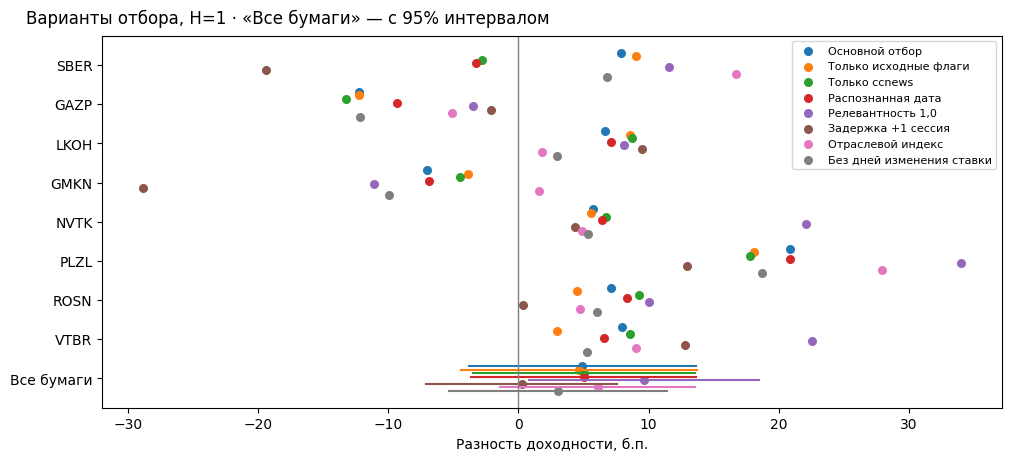

spec,N_on,N_off,beta_bps,low_bps,high_bps,p
Основной отбор,"2,269","1,733",4.9,-3.8,13.7,0.270
Только исходные флаги,"2,366","1,636",4.7,-4.4,13.7,0.312
Только ccnews,"2,202","1,800",5.0,-3.5,13.6,0.247
Распознанная дата,"2,253","1,749",5.0,-3.7,13.7,0.256
"Релевантность 1,0","1,939","2,063",9.7,0.8,18.5,0.033
Задержка +1 сессия,"2,264","1,738",0.2,-7.1,7.6,0.948
Отраслевой индекс,"2,269","1,733",6.1,-1.4,13.6,0.110
Без дней изменения ставки,"2,168","1,644",3.0,-5.3,11.4,0.475


По бумагам p < 0,05 без поправки: 1 из 64 оценок.


In [27]:
SENSITIVITY_SPECS = OrderedDict([
    ("Основной отбор", {}),
    ("Только исходные флаги", {"policy": "metadata"}),
    ("Только ccnews", {"source": "ccnews"}),
    ("Распознанная дата", {"checked_dates_only": True}),
    ("Релевантность 1,0", {"relevance": 1.0}),
    ("Задержка +1 сессия", {"anchor_col": "anchor_plus1"}),
    ("Отраслевой индекс", {"target": "y_sector_1"}),
    ("Без дней изменения ставки", {"exclude_dates": rate_days}),
])
sens_rows = []
for specification, options in SENSITIVITY_SPECS.items():
    options = dict(options)
    target, excluded = options.pop("target", None), options.pop("exclude_dates", None)
    variant = panel_with_news(panel, news_links, **options)
    if target:
        variant = variant.assign(y_1=variant[target])
    if excluded is not None:
        variant = variant.loc[~variant.trade_date.isin(excluded)]
    for ticker, stock_data in variant.groupby("ticker"):
        sens_rows.append(dict(ticker=ticker, spec=specification, **estimate_news_association(stock_data, "n_clean", 1, sessions)))
    sens_rows.append(dict(ticker=ALL_STOCKS, spec=specification,
                          **estimate_news_association(variant, "n_clean", 1, sessions, pooled=True)))
sensitivity = pd.DataFrame(sens_rows)
sens_pooled = sensitivity.loc[sensitivity.ticker.eq(ALL_STOCKS)]
sens_stocks = sensitivity.loc[sensitivity.ticker.ne(ALL_STOCKS)]

rows = TICKERS + [ALL_STOCKS]
fig, ax = plt.subplots(figsize=(10, 4.5))
for index, (specification, estimates) in enumerate(sensitivity.groupby("spec", sort=False)):
    estimates = estimates.set_index("ticker").reindex(rows)
    height = np.arange(len(rows)) + (index - (len(SENSITIVITY_SPECS) - 1) / 2) * 0.09
    ax.scatter(estimates.beta_bps, height, label=specification, color=f"C{index}", s=30)
    total = estimates.loc[ALL_STOCKS]
    ax.plot([total.low_bps, total.high_bps], [height[-1]] * 2, color=f"C{index}", lw=1.5)
ax.set_yticks(np.arange(len(rows)), rows)
ax.invert_yaxis()
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Разность доходности, б.п.")
ax.legend(fontsize=8)
show_figure(fig, f"Варианты отбора, H=1 · «{ALL_STOCKS}» — с 95% интервалом")
show_table(sens_pooled[["spec", "N_on", "N_off", "beta_bps", "low_bps", "high_bps", "p"]],
           f"{ALL_STOCKS} по вариантам отбора, б.п. · HAC 95%", {c: "{:.1f}" for c in ["beta_bps", "low_bps", "high_bps"]})
print(f"По бумагам p < 0,05 без поправки: {int(sens_stocks.p.lt(0.05).sum())} из {int(sens_stocks.p.notna().sum())} оценок.")

## 08 · Прогноз

Модели: ноль, среднее по акции, Ridge (α = 10) по ценовым признакам с новостями и без; горизонт 1 сессия.
Новостные признаки — число новостей (логарифм и флаг наличия) и знак тональности дня, как в разделе 04; тип события в модель не входит.
Обучение на расширяющемся окне, проверка на каждом квартале 2025 с зазором 5 сессий.
Разность MSE — блочный bootstrap по датам (блок 20 сессий, 5 000 повторов).

fold,N,improvement_pct,low_pct,high_pct,news_MSE_to_zero
2025 Q1,480,0.2530,-0.2967,0.6822,1.004306
2025 Q2,472,0.2804,-0.2856,0.7043,1.016828
2025 Q3,522,0.2508,-0.6963,0.9733,0.994217
2025 Q4,514,-0.6716,-1.2972,0.0200,1.028203
Весь 2025,"1,988",0.1008,-0.2184,0.3944,1.010009


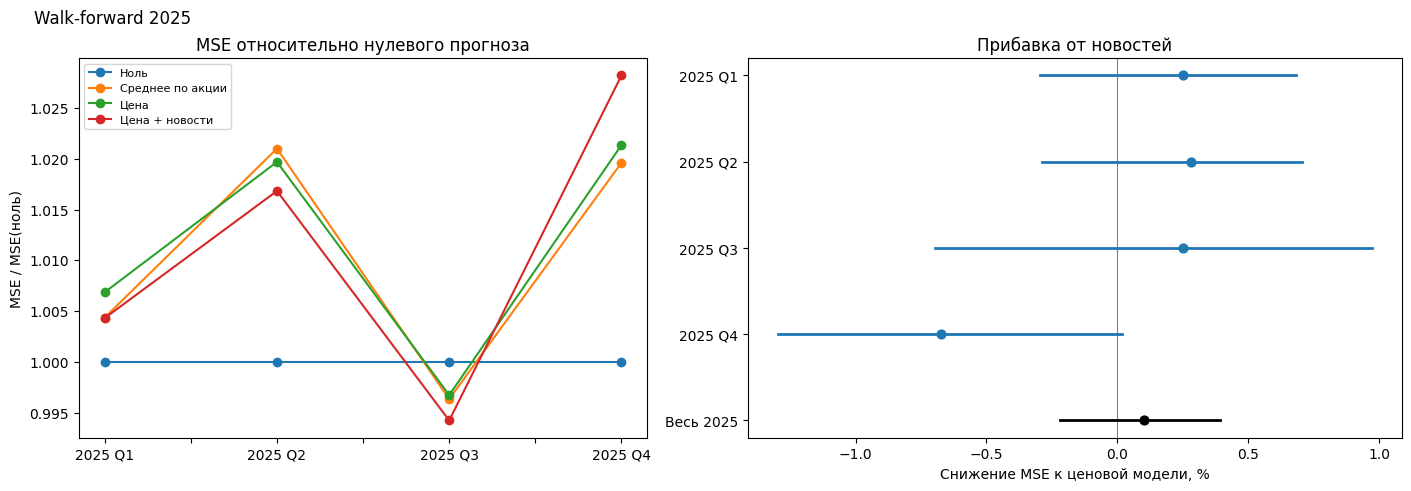

In [28]:
PRICE_FEATURES = ["lag_r", "lag_vol20", "lag_log_value"]
NEWS_FEATURES = ["log_news", "has_clean_news", "tone"]
panel["has_clean_news"] = panel.n_clean.gt(0).astype(float)
panel["tone"] = np.sign(panel.sent_mean).fillna(0)  # знак тональности дня, как в разделе 04; 0 — новостей нет
assert not any(c.startswith(("y_", "raw_y_", "end_")) for c in PRICE_FEATURES + NEWS_FEATURES)
checks["Будущие метки не входят в признаки модели"] = True

folds = make_folds(panel, sessions)
predictions = predict_walk_forward(panel, folds, PRICE_FEATURES, NEWS_FEATURES)
checks["Все модели оценены на одинаковых строках каждого квартала"] = True
loss_comparison = bootstrap_loss_comparison(predictions, sessions)
pooled_comparison = loss_comparison.loc[loss_comparison.fold.eq("Весь 2025")].iloc[0]
show_table(loss_comparison, "Снижение MSE от новостей к ценовой модели, % · 95% bootstrap",
           {"improvement_pct": "{:.4f}", "low_pct": "{:.4f}", "high_pct": "{:.4f}", "news_MSE_to_zero": "{:.6f}"})

mse_to_zero = (predictions.assign(error=(predictions.y - predictions.prediction) ** 2, zero=predictions.y ** 2)
               .groupby(["fold", "model"])[["error", "zero"]].mean().pipe(lambda f: f.error / f.zero).unstack())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), width_ratios=[1, 1.15])
mse_to_zero[["Ноль", "Среднее по акции", "Цена", "Цена + новости"]].plot(ax=axes[0], marker="o")
axes[0].set(title="MSE относительно нулевого прогноза", ylabel="MSE / MSE(ноль)", xlabel="")
axes[0].legend(title=None, fontsize=8)
axes[1].axvline(0, color="gray", linewidth=0.8)
for position, row in enumerate(loss_comparison.itertuples()):
    color = "black" if row.fold == "Весь 2025" else "C0"
    axes[1].plot([row.low_pct, row.high_pct], [position, position], color=color, lw=2)
    axes[1].scatter(row.improvement_pct, position, color=color, s=40, zorder=3)
axes[1].set_yticks(range(len(loss_comparison)), loss_comparison.fold)
axes[1].invert_yaxis()
axes[1].set(title="Прибавка от новостей", xlabel="Снижение MSE к ценовой модели, %")
show_figure(fig, "Walk-forward 2025")

## 09 · Выводы

In [29]:
thin_controls = main.loc[main.horizon.eq(1) & main.limited_support, "ticker"].tolist()
interval = "{:+.1f} б.п. [{:+.1f}; {:+.1f}]"
ratio = "×{:.2f} [{:.2f}; {:.2f}]"
all_news_days = event_reaction.iloc[0]
findings = [
    ("Выборка", f"{len(panel):,} акция-сессий, {len(news):,} документов, {int(news_links.clean.sum()):,} связей после отбора"),
    ("Карантин", f"{len(quarantined_eligible):,} связей, {quarantined_eligible.doc_id.nunique():,} документов"),
    ("Дата проверена", f"{news_links.loc[news_links.clean, 'date_checked'].mean():.1%} отобранных связей"),
    ("Время 00:00 UTC", f"{news.midnight_utc.mean():.1%} документов"),
    ("Цены", f"пустых или некорректных свечей: {int((~stock_days.valid_bar).sum())}; "
             f"разрывов ряда: {int(stock_days.scale_break.sum())}; открытий позже 10:05: {int(stock_days.late_open.sum())}"),
    ("Связь по бумагам, BY q < 0,05", f"{int(main.q_BY.lt(0.05).sum())} из {int(main.p.notna().sum())}"),
    *[(f"Связь, все бумаги, H={h}", interval.format(row.beta_bps, row.low_bps, row.high_bps)) for h, row in pooled_main.iterrows()],
    ("Мало данных, H=1", ", ".join(thin_controls) or "нет"),
    *[(f"Тональность, {row.target}", interval.format(row.beta_bps, row.low_bps, row.high_bps) + " по всем бумагам; по бумагам BY q < 0,05: "
       + f"{tone_summary.loc[row.target, 'q_BY_ниже_005']} из {tone_summary.loc[row.target, 'оценено']}") for row in tone_pooled.itertuples()],
    ("Дни с новостями, |AR| к среднему дню",
     "сессия публикации " + ratio.format(*all_news_days[["публикация_×", "публикация_low", "публикация_high"]])
     + ", следующая " + ratio.format(*all_news_days[["следующая_×", "следующая_low", "следующая_high"]])),
    ("Варианты отбора, p < 0,05", f"по бумагам {int(sens_stocks.p.lt(0.05).sum())} из {int(sens_stocks.p.notna().sum())}, "
                                  f"все бумаги — {int(sens_pooled.p.lt(0.05).sum())} из {len(sens_pooled)}"),
    ("Реакция на пост, |AR|", "за 10 мин до ×{:.1f}, минута поста ×{:.1f}, через 1–10 мин ×{:.1f}".format(
        *intraday_summary.loc[["−10…−1", "минута поста", "+1…+10"], ("|AR|, раз к обычному", "оценка")])),
    ("Продолжение после поста", "{:+.1f} б.п. [{:+.1f}; {:+.1f}] к контролю".format(
        *continuation_summary.set_index("ряд").loc["разница", ["оценка", "low", "high"]])),
    *[(f"Знак GPT × AR внутри дня, {row.окно}", interval.format(row.оценка, row.low, row.high))
      for row in intraday_sign.iloc[[0, 1, 2, 3, 7]].itertuples()],
    ("Посты по дням, |AR|", "день −1 ×{:.2f}, день 0 ×{:.2f}, день +1 ×{:.2f}".format(
        *daily_abs_profile.loc[[-1, 0, 1], "оценка"])),
    *[(f"Продолжение дня 0, {row.окно}", f"{row.оценка:+.1f} б.п. [{row.low:+.1f}; {row.high:+.1f}]")
      for row in daily_continuation.itertuples()],
    ("Продолжение дня 0 без одной бумаги", leave_one_out_note),
    *[(f"Знак GPT × AR, {window}", "{:+.1f} б.п. [{:+.1f}; {:+.1f}]".format(*sign_reaction.loc[window, ["знак × AR", "low", "high"]]))
      for window in SIGN_WINDOWS],
    ("Прибавка к цене, 2025", f"{pooled_comparison.improvement_pct:.3f}% [{pooled_comparison.low_pct:.3f}; {pooled_comparison.high_pct:.3f}]"),
    ("MSE / MSE(ноль)", f"{pooled_comparison.news_MSE_to_zero:.6f}"),
]
show_table(pd.DataFrame(findings, columns=["показатель", "значение"]), "Итоги")
if pooled_comparison.low_pct > 0:
    print("Интервал прибавки выше нуля: нужна проверка на новом периоде.")
elif pooled_comparison.high_pct < 0:
    print("Интервал прибавки ниже нуля: новости ухудшают прогноз.")
else:
    print("Интервал прибавки включает ноль: улучшение не подтверждено.")

показатель,значение
Выборка,"4,080 акция-сессий, 44,196 документов, 14,688 связей после отбора"
Карантин,"3,324 связей, 3,253 документов"
Дата проверена,97.6% отобранных связей
Время 00:00 UTC,76.0% документов
Цены,пустых или некорректных свечей: 11; разрывов ряда: 1; открытий позже 10:05: 9
"Связь по бумагам, BY q < 0,05",0 из 24
"Связь, все бумаги, H=1",+4.9 б.п. [-3.8; +13.7]
"Связь, все бумаги, H=3",+4.3 б.п. [-12.9; +21.5]
"Связь, все бумаги, H=5",+8.0 б.п. [-15.1; +31.1]
"Мало данных, H=1","SBER, VTBR"


Интервал прибавки включает ноль: улучшение не подтверждено.


- **Данные.** Исходные флаги пропускали много ошибок дат (почти все — Регнум); основной результат посчитан после карантина. У 76% документов время 00:00 UTC, поэтому новости из S3 годятся только для дневного горизонта.
- **Новости → следующие сессии.** Наличие новостей доходность не сдвигает: по всем бумагам +4,9 б.п. [−3,8; +13,7] за сессию, на 3 и 5 сессиях интервалы тоже включают ноль, по отдельным бумагам после поправки значимых оценок нет. В 7 из 8 вариантов отбора вывод тот же; при релевантности 1,0 — +9,7 б.п. [+0,8; +18,5], на границе значимости.
- **Тональность.** В сессию публикации доходность при положительных новостях выше, чем при отрицательных, на 13,6 б.п. [+3,2; +24,1]. В следующую сессию — на 10,9 б.п. [+0,4; +21,4]: это граница значимости, знаки по бумагам разные, после поправки значимых бумаг нет. В прогнозе 2025 года улучшение от тональности не подтвердилось, так что считать это сигналом рано.
- **Типы событий.** Дни с новостями по размеру движения не отличаются от среднего дня бумаги (×1,00 [0,95; 1,05]); новизна тоже ничего не различает. Из типов выделяются только дивидендные новости: ×1,37 [1,08; 1,74] в сессию публикации, без поправки на число типов.
- **Внутри дня: размер движения.** Цена реагирует на посты MarketTwits, но начинает двигаться ещё до поста: канал запаздывает за рынком. За 10 минут до поста |AR| выше обычного в 1,33 раза при фоне дня с постом ×1,1–1,2 (окна за час до и через полчаса после). С 2022 года реакция сильнее: в минуту поста ×1,8–3,6 против ×1,1–1,25 в 2018–2021 годах.
- **Внутри дня: знак новости.** По GPT-меткам (338 событий нефтегаза) цена идёт в сторону новости уже за час до поста: +5,6 и +4,1 б.п. в окнах −60…−11 и −10…−1. После поста — только в первую минуту: +1,9 б.п. [+0,5; +3,3]. При входе через минуту после поста за следующий час выходит +4,5 б.п. [−0,6; +9,4]: от нуля не отличить. По всем 5 072 событиям продолжение движения после поста — около 1 б.п., меньше издержек на сделку.
- **По дням** реакция слабая (+17% к обычному |AR| в день поста). Знак GPT-метки совпадает с движением цены в день поста и в дни перед ним; после поста дрейфа по знаку нет. Движение дня поста продолжается в дни +2…+5 на 12,6 б.п. к контролю [+4,8; +20,6], но это эффект одной бумаги: без GAZP — +1,7 б.п. [−6,3; +9,6].
- **Прогноз.** Улучшение прогноза 2025 года от новостей — их числа и знака тональности — не подтверждено: +0,10% MSE [−0,22; +0,39]. Модели с новостями и без них не лучше нулевого прогноза (MSE/MSE(ноль) ≈ 1,01).
- **Итог:** новости и посты в основном описывают уже случившееся движение цены; устойчивого сигнала о будущей доходности нет. После поста цена доходит в сторону новости за первую минуту, дальше дрейф от нуля не отличить. Слабые эффекты на границе значимости — тональность в следующую сессию и новости с релевантностью 1,0 — нужно проверить на новом периоде. Дальше — ручная проверка дат и привязки к компаниям.